<h1>Train — EfficientNet-B0</h1>

Trains and evaluates EfficientNet-B0 using the tuned hyperparameters from `ARCH_HYPERPARAMS["efficientnet_b0"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["efficientnet_b0"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"EfficientNet-B0: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

EfficientNet-B0: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, tuned value = 96)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with EfficientNet-B0)
# ---------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# EfficientNet's classifier is nn.Sequential(Dropout, Linear) — swap out
# just the Linear layer for our (optionally deeper) classifier head, same
# as the fc/classifier swaps used for the other architectures.
in_f = model.classifier[1].in_features
model.classifier[1] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[EfficientNet-B0] Using gradient accumulation: 6 micro-batches per optimizer step (effective batch size ≈ micro_batch x 6).


[EfficientNet-B0] Epoch   1/100 | LR: 8.76e-04 | train loss 0.7687 acc 0.652 | val loss 0.5365 acc 0.789 *


[EfficientNet-B0] Epoch   2/100 | LR: 8.76e-04 | train loss 0.4174 acc 0.808 | val loss 0.5618 acc 0.793


[EfficientNet-B0] Epoch   3/100 | LR: 8.76e-04 | train loss 0.3530 acc 0.843 | val loss 0.6303 acc 0.765


[EfficientNet-B0] Epoch   4/100 | LR: 8.76e-04 | train loss 0.2365 acc 0.893 | val loss 0.5480 acc 0.799


...

[EfficientNet-B0] Epoch  11/100 | LR: 8.76e-04 | train loss 0.1346 acc 0.948 | val loss 0.8231 acc 0.777


[EfficientNet-B0] Epoch  12/100 | LR: 8.76e-04 | train loss 0.1032 acc 0.961 | val loss 0.6597 acc 0.817


[EfficientNet-B0] Epoch  13/100 | LR: 8.76e-04 | train loss 0.0863 acc 0.969 | val loss 0.7313 acc 0.836


[EfficientNet-B0] Epoch  14/100 | LR: 8.76e-04 | train loss 0.0657 acc 0.973 | val loss 0.6646 acc 0.836


[EfficientNet-B0] Epoch  15/100 | LR: 8.76e-04 | train loss 0.0758 acc 0.964 | val loss 0.6524 acc 0.811

[EfficientNet-B0] No val loss improvement for 10 epochs — stopping early at epoch 15.

[EfficientNet-B0] Restored best checkpoint (val loss = 0.4737)


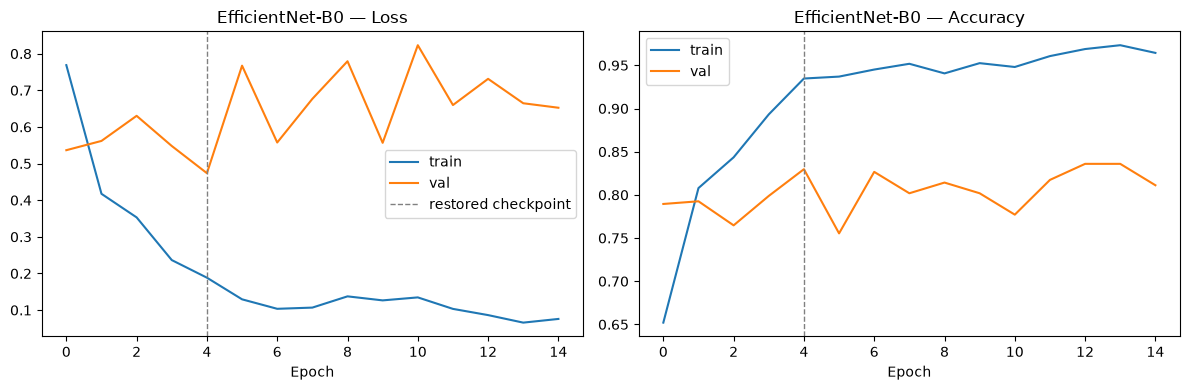

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "EfficientNet-B0", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "EfficientNet-B0")

## Evaluate on the test set

[EfficientNet-B0] Test accuracy: 0.789


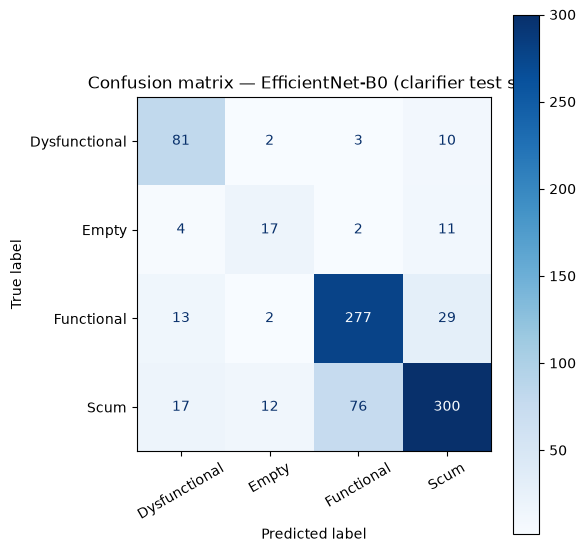

               precision    recall  f1-score   support

Dysfunctional      0.704     0.844     0.768        96
        Empty      0.515     0.500     0.507        34
   Functional      0.774     0.863     0.816       321
         Scum      0.857     0.741     0.795       405

     accuracy                          0.789       856
    macro avg      0.713     0.737     0.721       856
 weighted avg      0.795     0.789     0.788       856



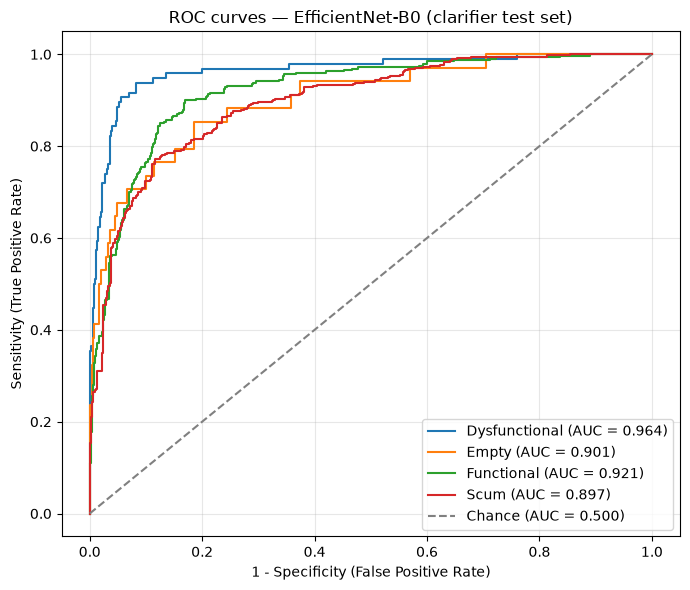

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.964
  Empty          : 0.901
  Functional     : 0.921
  Scum           : 0.897

Mean AUC (over 4/4 classes with test examples): 0.921


(np.float64(0.7885514018691588),
 {'Dysfunctional': 0.9639665570175439,
  'Empty': 0.9014956347502504,
  'Functional': 0.9207732844207647,
  'Scum': 0.8967726040896773})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "EfficientNet-B0", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("EfficientNet-B0", "efficientnet_b0")

Saved results to ../results/clarifier_noaug/results_clarifier_efficientnet_b0_chronological.pkl


Saved model weights to ../models/pad/clarifier_efficientnet_b0_cnn.pt
